# Reconstruct a reciprocal lattice from images

This example supplies only grayscale images and detector calibration to the estimator. Synthetic lattice parameters and rotations are used to generate images and check the result, never for matching. See the README for assumptions and limitations.


In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "utils").exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from examples.reconstruct_lattice_demo import synthetic_batch
from utils.reconstruct_lattice import reconstruct_images


In [2]:
images, calibrations, true_basis = synthetic_batch()
result = reconstruct_images(images, calibrations, tolerance=0.003, max_trials=6000, peak_options={'threshold': 254})
print("Reciprocal basis (rows):", result["basis"], sep="\n")
print("Indexed fraction:", result["inliers"].mean())
print("Recovered / true cell volume:", abs(np.linalg.det(result["basis"]) / np.linalg.det(true_basis)))
print("Azimuth, elevation, roll (degrees):", result["azimuth_elevation_roll"], sep="\n")


Reciprocal basis (rows):
[[ 5.10012263e-02  5.72744656e-07  1.03822373e-05]
 [-1.20036868e-02 -6.30012833e-02  9.99681008e-07]
 [ 1.09798967e-02  2.30076488e-02  7.59876134e-02]]
Indexed fraction: 1.0
Recovered / true cell volume: 0.9998664221369541
Azimuth, elevation, roll (degrees):
[[0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [1.99904004e+00 1.73195445e-03 1.09042690e-03]
 [3.99820100e+00 3.48570001e-03 2.27336886e-03]
 [5.99720537e+00 5.14136336e-03 3.34861975e-03]
 [7.99637437e+00 6.95605058e-03 4.62877225e-03]]


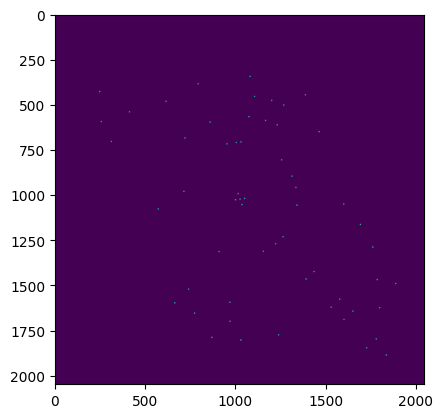

In [19]:
plt.imshow(images[4] < 255)

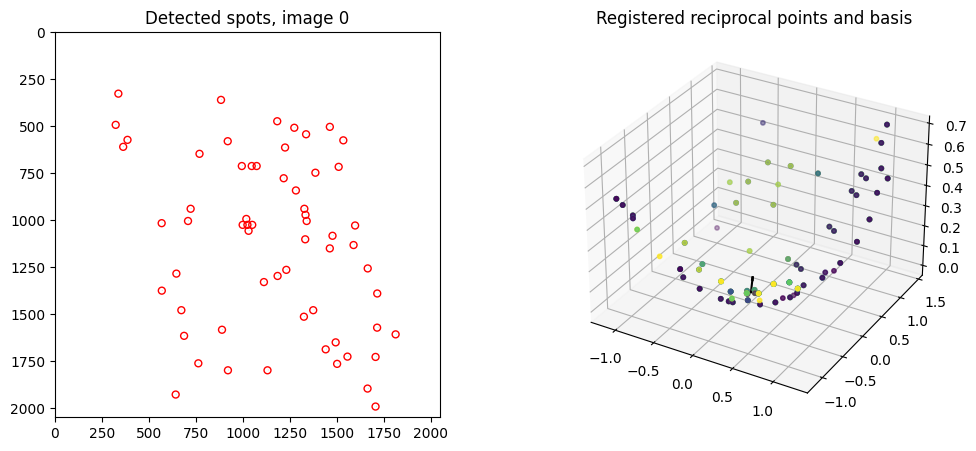

In [3]:
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(121)
ax.imshow(images[0], cmap="gray")
uv = result["uv_points"][0]
ax.scatter(*uv.T, s=25, facecolors="none", edgecolors="red")
ax.set_title("Detected spots, image 0")
ax = fig.add_subplot(122, projection="3d")
p = result["points"]
ax.scatter(*p.T, c=result["image_ids"], s=10)
for v in result["basis"]:
    ax.quiver(0, 0, 0, *v, color="black")
ax.set_title("Registered reciprocal points and basis")
plt.show()


For real data, replace `images` and `calibrations` above. Use `peak_options={"dark": False, "threshold": ...}` for bright spots. The arbitrary perspective render in `spherical_intersections.ipynb` is not compatible with this detector model; rasterize `project_reflections_2D` coordinates instead.
